# T13 – TN1: Ảnh hưởng của data leakage và cách chia dữ liệu

**Mục tiêu:** định lượng mức thay đổi hiệu năng khi dùng bộ đặc trưng thông thường so với bộ đặc trưng sạch, đồng thời so sánh chia ngẫu nhiên với chia theo thời gian.

Thiết kế thí nghiệm 2×2:

| Bộ đặc trưng | Chia ngẫu nhiên | Chia theo thời gian |
|---|---|---|
| Conventional | (1) | (2) |
| Clean | (3) | (4) |

Mỗi ô chạy cùng ba mô hình đã tinh chỉnh ở T10–T12: Logistic Regression, Random Forest và Gradient Boosting (LightGBM). Dùng siêu tham số đã lưu, **không tinh chỉnh lại theo từng ô**, để phép so sánh tập trung vào tác động của bộ đặc trưng và cách chia.

**Metric chính:** PR-AUC (Average Precision), phù hợp với mục tiêu phát hiện booking bị hủy và tỷ lệ lớp không cân bằng. F1, Precision, Recall và ROC-AUC là metric bổ sung. Tất cả đánh giá trong notebook này dùng validation; tập test được giữ nguyên cho T16.

> Lưu ý theo quyết định kỹ thuật hiện tại của repository: cả hai bộ đều không đưa `reservation_status` và `reservation_status_date` vào mô hình. Bộ conventional giữ thêm 7 cột có nguy cơ leakage khó nhận ra; xem `docs/decisions.md` và `docs/feature_decisions.md`. Đây là cách triển khai TN1 đã được chốt trong mã nguồn, thay vì chỉ bỏ `reservation_status` như mô tả ban đầu trong kế hoạch.

In [1]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
assert (ROOT / "src").is_dir(), f"Không tìm thấy src từ {Path.cwd()}"

PROJECT_ROOT = ROOT
RESULTS_PATH = PROJECT_ROOT / "reports" / "results" / "results.csv"
SUMMARY_PATH = PROJECT_ROOT / "reports" / "results" / "tn1_summary.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Results:", RESULTS_PATH.relative_to(PROJECT_ROOT).as_posix())

Results: reports/results/results.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from src.config import (
    RANDOM_STATE, TARGET_COLUMN,
    CLEAN_CATEGORICAL_FEATURES, CONVENTIONAL_CATEGORICAL_FEATURES,
)
from src.data import load_raw
from src.evaluate import RESULT_COLUMNS, evaluate_classification
from src.features import (
    add_features, ENGINEERED_CATEGORICAL_FEATURES,
    ENGINEERED_NUMERIC_FEATURES,
)
from src.preprocess import clean_data, build_model_pipeline
from src.split import temporal_split, random_split

TARGET = TARGET_COLUMN
MODEL_NAMES = ["LogisticRegressionTuned", "RandomForest", "GradientBoosting"]
FEATURE_SET_NAMES = ["conventional", "clean"]
SPLIT_NAMES = ["random", "temporal"]
THRESHOLD = 0.5
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Đọc dữ liệu và chuẩn bị hai bộ đặc trưng

`clean_data` và `add_features` là các bước biến đổi cố định theo pipeline chung. Cột `arrival_date` chỉ phục vụ chia theo thời gian, không được đưa vào đặc trưng. Bộ clean gồm 22 cột đã chốt cộng `arrival_weekday`; bộ conventional bổ sung 7 cột theo `docs/decisions.md` và cũng có `arrival_weekday`.

In [3]:
raw = load_raw()
cleaned = clean_data(raw)
df = add_features(cleaned)

CLEAN_NUMERIC = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "total_of_special_requests",
]
EXTRA_CONVENTIONAL_NUMERIC = [
    "arrival_date_year", "booking_changes", "days_in_waiting_list",
    "required_car_parking_spaces",
]

FEATURES_BY_SET = {
    "clean": CLEAN_NUMERIC + list(ENGINEERED_NUMERIC_FEATURES)
             + list(CLEAN_CATEGORICAL_FEATURES)
             + list(ENGINEERED_CATEGORICAL_FEATURES),
    "conventional": CLEAN_NUMERIC + EXTRA_CONVENTIONAL_NUMERIC
                    + list(ENGINEERED_NUMERIC_FEATURES)
                    + list(CONVENTIONAL_CATEGORICAL_FEATURES)
                    + list(ENGINEERED_CATEGORICAL_FEATURES),
}
NUMERIC_BY_SET = {
    "clean": CLEAN_NUMERIC + list(ENGINEERED_NUMERIC_FEATURES),
    "conventional": CLEAN_NUMERIC + EXTRA_CONVENTIONAL_NUMERIC
                    + list(ENGINEERED_NUMERIC_FEATURES),
}
CATEGORICAL_BY_SET = {
    "clean": list(CLEAN_CATEGORICAL_FEATURES) + list(ENGINEERED_CATEGORICAL_FEATURES),
    "conventional": list(CONVENTIONAL_CATEGORICAL_FEATURES)
                    + list(ENGINEERED_CATEGORICAL_FEATURES),
}

FORBIDDEN = {TARGET, "reservation_status", "reservation_status_date", "arrival_date"}
for set_name, features in FEATURES_BY_SET.items():
    assert len(features) == len(set(features)), f"Feature trùng trong {set_name}"
    assert not (set(features) & FORBIDDEN), f"Có target/leakage trong {set_name}"
    assert set(features) <= set(df.columns), f"Thiếu cột trong {set_name}: {set(features) - set(df.columns)}"
    assert set(NUMERIC_BY_SET[set_name]) | set(CATEGORICAL_BY_SET[set_name]) == set(features)

print("Dataset sau clean:", df.shape)
print("Số feature:", {k: len(v) for k, v in FEATURES_BY_SET.items()})
display(pd.DataFrame({
    "feature_set": list(FEATURES_BY_SET),
    "n_features": [len(FEATURES_BY_SET[k]) for k in FEATURES_BY_SET],
    "n_numeric": [len(NUMERIC_BY_SET[k]) for k in FEATURES_BY_SET],
    "n_categorical": [len(CATEGORICAL_BY_SET[k]) for k in FEATURES_BY_SET],
}).set_index("feature_set"))

Dataset sau clean: (119205, 34)
Số feature: {'clean': 23, 'conventional': 30}


,n_features,n_numeric,n_categorical
feature_set,,,
clean,23,13,10
conventional,30,17,13


## 2. Thiết lập hai cách chia

- **Temporal:** dùng mốc chung của nhóm: train trước `2017-01-01`, validation từ `2017-01-01` đến trước `2017-07-01`, phần còn lại là test giữ riêng.
- **Random:** dùng `random_split` trong `src/split.py`, seed `RANDOM_STATE=42`, stratify theo target; tỷ lệ train/validation/test theo mặc định đã thống nhất.

Trong cả hai trường hợp, chỉ train và validation được dùng ở T13. Không đọc điểm số test, không dùng test để chọn mô hình hoặc tham số.

In [4]:
SPLITS = {}

train_t, valid_t, test_t = temporal_split(
    df, train_end="2017-01-01", valid_end="2017-07-01", date_col="arrival_date"
)
SPLITS["temporal"] = (train_t, valid_t, test_t)

train_r, valid_r, test_r = random_split(
    df, target_col=TARGET, random_state=RANDOM_STATE, stratify=True
)
SPLITS["random"] = (train_r, valid_r, test_r)

split_summary = pd.DataFrame([
    {
        "split": split_name,
        "train_rows": len(train),
        "validation_rows": len(valid),
        "held_out_test_rows": len(test),
        "train_cancel_rate": train[TARGET].mean(),
        "validation_cancel_rate": valid[TARGET].mean(),
    }
    for split_name, (train, valid, test) in SPLITS.items()
]).set_index("split")
display(split_summary)

assert all(len(valid) > 0 for _, valid, _ in SPLITS.values())
assert all(len(test) > 0 for _, _, test in SPLITS.values())

,train_rows,validation_rows,held_out_test_rows,train_cancel_rate,validation_cancel_rate
split,,,,,
temporal,78586,30386,10233,0.3622,0.3928
random,78555,30398,10252,0.3708,0.3708


## 3. Nạp siêu tham số T10–T12

Dùng đúng các file JSON hiện có trong `models/`. Không thay đổi tham số giữa các điều kiện TN1. Nếu thành viên cập nhật kết quả T11/T12 sau thời điểm tạo notebook, cần cập nhật các file JSON tương ứng trước khi chạy.

In [5]:
PARAMS = {
    "LogisticRegressionTuned": json.loads(
        (PROJECT_ROOT / "models" / "logistic_regression_best_params.json").read_text(encoding="utf-8")
    ),
    "RandomForest": json.loads(
        (PROJECT_ROOT / "models" / "random_forest_best_params.json").read_text(encoding="utf-8")
    ),
    "GradientBoosting": json.loads(
        (PROJECT_ROOT / "models" / "gradient_boosting_best_params.json").read_text(encoding="utf-8")
    ),
}

print(json.dumps(PARAMS, indent=2, ensure_ascii=False))

def make_estimator(model_name, params):
    params = dict(params)
    if model_name == "LogisticRegressionTuned":
        return LogisticRegression(**params)
    if model_name == "RandomForest":
        return RandomForestClassifier(**params)
    if model_name == "GradientBoosting":
        return LGBMClassifier(**params)
    raise ValueError(f"Model không được hỗ trợ: {model_name}")

def make_pipeline(model_name, feature_set, X_train):
    estimator = make_estimator(model_name, PARAMS[model_name])
    return build_model_pipeline(
        X_train,
        estimator,
        numeric_features=NUMERIC_BY_SET[feature_set],
        categorical_features=CATEGORICAL_BY_SET[feature_set],
        scale_numeric=(model_name == "LogisticRegressionTuned"),
    )

{
  "LogisticRegressionTuned": {
    "C": 0.1,
    "class_weight": null,
    "max_iter": 3000,
    "penalty": "l2",
    "random_state": 42,
    "solver": "lbfgs"
  },
  "RandomForest": {
    "class_weight": "balanced_subsample",
    "max_depth": 20,
    "max_features": "sqrt",
    "min_samples_leaf": 20,
    "n_estimators": 300,
    "n_jobs": -1,
    "random_state": 42
  },
  "GradientBoosting": {
    "colsample_bytree": 0.9,
    "learning_rate": 0.05,
    "max_depth": -1,
    "min_child_samples": 30,
    "n_estimators": 300,
    "n_jobs": -1,
    "num_leaves": 31,
    "objective": "binary",
    "random_state": 42,
    "subsample": 0.9,
    "verbosity": -1
  }
}


## 4. Chạy thí nghiệm 2×2 × 3 mô hình

Mỗi pipeline fit preprocessing riêng trên tập train của đúng điều kiện. Đánh giá validation tại ngưỡng 0,5. PR-AUC và ROC-AUC được tính từ xác suất dự đoán; các metric còn lại dùng nhãn dự đoán ở ngưỡng 0,5.

In [6]:
result_rows = []

for split_name in SPLIT_NAMES:
    train, valid, _held_out_test = SPLITS[split_name]
    y_train = train[TARGET]
    y_valid = valid[TARGET]

    for feature_set in FEATURE_SET_NAMES:
        features = FEATURES_BY_SET[feature_set]
        X_train = train[features]
        X_valid = valid[features]

        for model_name in MODEL_NAMES:
            print(f"Fit: split={split_name}, feature_set={feature_set}, model={model_name}")
            pipeline = make_pipeline(model_name, feature_set, X_train)
            pipeline.fit(X_train, y_train)
            y_score = pipeline.predict_proba(X_valid)[:, 1]
            y_pred = (y_score >= THRESHOLD).astype(int)
            metrics = evaluate_classification(y_valid, y_pred, y_score)

            result_rows.append({
                "model_name": model_name,
                "experiment": "TN1",
                "feature_set": feature_set,
                "split": split_name,
                "train_hotel": "all",
                "eval_hotel": "all",
                "eval_set": "validation",
                "n_eval": len(valid),
                "eval_cancel_rate": float(y_valid.mean()),
                "threshold": THRESHOLD,
                "params": json.dumps(PARAMS[model_name], sort_keys=True),
                **metrics,
            })

results_tn1 = pd.DataFrame(result_rows)
assert len(results_tn1) == 12
assert not results_tn1.isna()[["average_precision", "f1", "roc_auc"]].any().any()
display(results_tn1[[
    "model_name", "feature_set", "split", "n_eval",
    "average_precision", "f1", "precision", "recall", "roc_auc",
]])

Fit: split=random, feature_set=conventional, model=LogisticRegressionTuned


Fit: split=random, feature_set=conventional, model=RandomForest


Fit: split=random, feature_set=conventional, model=GradientBoosting


Fit: split=random, feature_set=clean, model=LogisticRegressionTuned


Fit: split=random, feature_set=clean, model=RandomForest


Fit: split=random, feature_set=clean, model=GradientBoosting


... (3 outputs left out)

Fit: split=temporal, feature_set=clean, model=LogisticRegressionTuned


Fit: split=temporal, feature_set=clean, model=RandomForest


Fit: split=temporal, feature_set=clean, model=GradientBoosting


,model_name,feature_set,split,n_eval,average_precision,f1,precision,recall,roc_auc
0,LogisticRegressionTuned,conventional,random,30398,0.8634,0.7395,0.8023,0.6857,0.9054
1,RandomForest,conventional,random,30398,0.9188,0.8261,0.8077,0.8454,0.9448
2,GradientBoosting,conventional,random,30398,0.9271,0.8281,0.8519,0.8057,0.9513
3,LogisticRegressionTuned,clean,random,30398,0.7983,0.6904,0.7748,0.6226,0.8310
4,RandomForest,clean,random,30398,0.8599,0.7562,0.7705,0.7425,0.8905
5,GradientBoosting,clean,random,30398,0.8653,0.7449,0.8382,0.6703,0.8934
6,LogisticRegressionTuned,conventional,temporal,30386,0.8554,0.7515,0.7640,0.7394,0.8905
7,RandomForest,conventional,temporal,30386,0.8693,0.7519,0.8351,0.6838,0.9044
8,GradientBoosting,conventional,temporal,30386,0.8717,0.7429,0.8410,0.6654,0.9044
9,LogisticRegressionTuned,clean,temporal,30386,0.7855,0.6584,0.7621,0.5795,0.8222


## 5. Bảng 2×2 tổng hợp

Bảng dưới đây lấy trung bình PR-AUC của ba mô hình trong mỗi điều kiện để thể hiện xu hướng tổng quát. Không dùng giá trị trung bình này thay cho kết quả từng mô hình; bảng chi tiết ở trên và các dòng trong `results.csv` giữ lại kết quả riêng của từng mô hình.

In [7]:
summary = (
    results_tn1.groupby(["feature_set", "split"])
    .agg(
        mean_pr_auc=("average_precision", "mean"),
        mean_f1=("f1", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        n_models=("model_name", "nunique"),
    )
    .reset_index()
)

pr_auc_matrix = summary.pivot(index="feature_set", columns="split", values="mean_pr_auc")
f1_matrix = summary.pivot(index="feature_set", columns="split", values="mean_f1")
print("Bảng 2×2 – PR-AUC trung bình của 3 mô hình")
display(pr_auc_matrix)
print("Bảng 2×2 – F1 trung bình của 3 mô hình")
display(f1_matrix)

summary.to_csv(SUMMARY_PATH, index=False)
print("Saved:", SUMMARY_PATH.relative_to(PROJECT_ROOT).as_posix())

Bảng 2×2 – PR-AUC trung bình của 3 mô hình


split,random,temporal
feature_set,,
clean,0.8412,0.7944
conventional,0.9031,0.8655


Bảng 2×2 – F1 trung bình của 3 mô hình


split,random,temporal
feature_set,,
clean,0.7305,0.6593
conventional,0.7979,0.7488


Saved: reports/results/tn1_summary.csv


## 6. Hình so sánh PR-AUC

Biểu đồ thể hiện từng mô hình trong bốn điều kiện. Quan sát chênh lệch giữa conventional và clean trong cùng kiểu chia để thảo luận tác động của các cột có nguy cơ leakage; quan sát random và temporal trong cùng bộ feature để thảo luận tác động của cách chia. Không diễn giải chênh lệch như một ước lượng nhân quả tuyệt đối vì validation ở hai kiểu chia có phân phối và khoảng thời gian khác nhau.

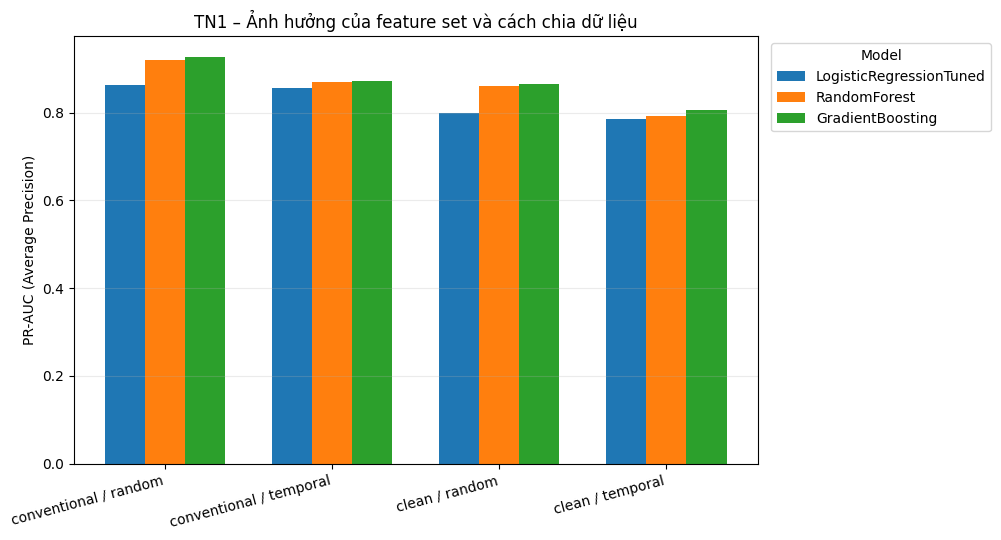

Saved: reports/figures/tn1_leakage_split_comparison.png


In [8]:
plot_data = results_tn1.copy()
plot_data["condition"] = plot_data["feature_set"] + " / " + plot_data["split"]
conditions = ["conventional / random", "conventional / temporal", "clean / random", "clean / temporal"]
models = MODEL_NAMES
x = np.arange(len(conditions))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, model_name in enumerate(models):
    values = [
        plot_data.loc[
            (plot_data["model_name"] == model_name)
            & (plot_data["condition"] == condition),
            "average_precision",
        ].iloc[0]
        for condition in conditions
    ]
    ax.bar(x + (i - 1) * width, values, width, label=model_name)

ax.set_xticks(x)
ax.set_xticklabels(conditions, rotation=15, ha="right")
ax.set_ylabel("PR-AUC (Average Precision)")
ax.set_title("TN1 – Ảnh hưởng của feature set và cách chia dữ liệu")
ax.legend(title="Model", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
figure_path = FIGURES_DIR / "tn1_leakage_split_comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", figure_path.relative_to(PROJECT_ROOT).as_posix())

## 7. Ghi các dòng T13 vào `results.csv`

Notebook chỉ thay thế các dòng thuộc chính thí nghiệm `TN1` của ba mô hình, không xóa hoặc ghi đè kết quả `main` của T09–T12 hay kết quả thí nghiệm khác. Cột `eval_set` là `validation`; không ghi kết quả test.

In [9]:
if RESULTS_PATH.exists() and RESULTS_PATH.stat().st_size > 0:
    existing = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
    if list(existing.columns) != RESULT_COLUMNS:
        raise ValueError("results.csv không khớp RESULT_COLUMNS trong src/evaluate.py")
    owned = (
        existing["experiment"].str.upper().eq("TN1")
        & existing["model_name"].isin(MODEL_NAMES)
        & existing["eval_set"].eq("validation")
    )
    existing.loc[~owned].to_csv(RESULTS_PATH, index=False)
else:
    pd.DataFrame(columns=RESULT_COLUMNS).to_csv(RESULTS_PATH, index=False)

for row in result_rows:
    # Dùng append_result để giữ schema chung của nhóm.
    from src.evaluate import append_result
    append_result(row, path=str(RESULTS_PATH))

saved = pd.read_csv(RESULTS_PATH)
tn1_saved = saved[
    saved["experiment"].eq("TN1")
    & saved["model_name"].isin(MODEL_NAMES)
    & saved["eval_set"].eq("validation")
]
assert len(tn1_saved) == 12
print("T13 rows saved:", len(tn1_saved))
display(tn1_saved[[
    "model_name", "feature_set", "split", "average_precision", "f1", "roc_auc"
]].sort_values(["feature_set", "split", "model_name"]))

T13 rows saved: 12


,model_name,feature_set,split,average_precision,f1,roc_auc
15,GradientBoosting,clean,random,0.8653,0.7449,0.8934
13,LogisticRegressionTuned,clean,random,0.7983,0.6904,0.8310
14,RandomForest,clean,random,0.8599,0.7562,0.8905
21,GradientBoosting,clean,temporal,0.8055,0.6580,0.8425
19,LogisticRegressionTuned,clean,temporal,0.7855,0.6584,0.8222
20,RandomForest,clean,temporal,0.7924,0.6615,0.8384
12,GradientBoosting,conventional,random,0.9271,0.8281,0.9513
10,LogisticRegressionTuned,conventional,random,0.8634,0.7395,0.9054
11,RandomForest,conventional,random,0.9188,0.8261,0.9448
18,GradientBoosting,conventional,temporal,0.8717,0.7429,0.9044


## 8. Kiểm tra và diễn giải kết quả

Khi đọc kết quả, cần trả lời tối thiểu:

1. Với cùng cách chia, conventional có PR-AUC cao hơn clean bao nhiêu? Mức tăng có xuất hiện ở cả ba mô hình không?
2. Với cùng bộ feature, random có kết quả cao hơn temporal không? Chênh lệch có nhất quán giữa các mô hình không?
3. Có trường hợp mô hình đạt điểm rất cao ở conventional/random nhưng giảm rõ ở clean/temporal không? Điều này gợi ý kết quả “đẹp ảo” do kết hợp đặc trưng có nguy cơ leakage và cách chia ngẫu nhiên.
4. Vì sao không thể kết luận mọi chênh lệch chỉ do leakage hoặc chỉ do split? Hai yếu tố có thể tương tác; hơn nữa validation random và temporal đại diện cho các mẫu/phân phối khác nhau.

**Không kết luận trước khi chạy notebook.** Số liệu trong báo cáo phải lấy từ `results.csv` và `tn1_summary.csv` sau khi chạy thành công.

### Sản phẩm bàn giao T13

- `notebooks/07_tn1_leakage_split.ipynb`
- `reports/results/results.csv`: 12 dòng `experiment=TN1`, mỗi mô hình × feature set × split.
- `reports/results/tn1_summary.csv`: bảng tổng hợp 2×2.
- `reports/figures/tn1_leakage_split_comparison.png`: hình so sánh PR-AUC.

Trước khi commit: Restart & Run All; xác nhận không có kết quả test trong notebook; kiểm tra diff `results.csv` để bảo đảm các dòng của thành viên khác còn nguyên.